# A/B Test of a First-Purchase Bonus for TikTok Users (Capstone project, part 2) / A/B-тест бонуса на первую покупку для пользователей из TikTok (Выпускной проект, часть 2)

Conclusions in English can be found at the end of the document.

Я работаю с быстрорастущим маркетплейсом, который уже нашёл свою нишу и начал приносить прибыль. Монетизация у маркетплейса работает так: он забирает комиссию 5% с каждой покупки пользователей. До недавнего времени здесь обходились отчётами в Excel, ориентировались на бухгалтерские сводки и интуицию. Но бизнес растёт, и стало понятно, что нужны настоящие продуктовые данные, системный взгляд и аналитика, которая не просто описывает проект, а развивает его.

В [первой части выпускного проекта](Marketplace%20Product%20Analysis%20-%20Metrics,%20Unit%20Economics,%20and%20Growth%20Points.ipynb) я исследовала, как чувствует себя продукт: кто приходит, кто остаётся, кто платит, кто уходит, на каких каналах и товарах держится рост и какие есть точки роста. По итогам исследования я предложила несколько гипотез.

Команда продукта рассмотрела мои гипотезы и на основании этого решила влиять на конверсию при помощи финансовых стимуляций. Так как ситуация со снижением выручки срочная и безотлагательная, пока я продолжала изучать данные, они подключили другого аналитика для подготовки дизайн документа, но само проведение эксперимента на мне. При формировании выводов A/B-теста мне нужно написать рекомендации по итогам теста и, если необходимо, описать проблемы, присутствующие в эксперименте.

# Дизайн эксперимента

## 1. Контекст и цель эксперимента

- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.  
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.  
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку

---

## 2. Формат эксперимента

- **Тип эксперимента:** Сплит-роллинг (rolling split)  
- **Канал:** Только пользователи, пришедшие с TikTok  
- **Группы:**  
  - **Контрольная (A):** пользователи TikTok без бонуса  
  - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку  
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации  
- **Период проведения:** 3 недели (фиксировано)

---

## 3. Ключевые метрики

### Основная метрика

- **Конверсия в первую покупку** — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку  
  - *Цель:* увеличить конверсию с помощью бонуса  
  - *Критерий успеха:* статистически значимый рост конверсии в тестовой группе

### Вспомогательные метрики

- **ARPU** (средняя выручка на пользователя TikTok)  
- **ARPPU** (средняя выручка на покупателя TikTok)  
- **AOV** (средний чек TikTok)

### Барьерная метрика

- **Общая выручка от пользователей TikTok**

---

## 4. Размеры групп и запуск

- **Целевая аудитория:** только пользователи TikTok  
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента  
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


In [1]:
# Импортируем необходимые библиотеки
import pandas as pd # версия 2.3.3
import matplotlib.pyplot as plt # версия 3.9.4
import scipy # версия 1.13.1
import statsmodels # версия 0.14.6
import numpy as np # версия 2.0.2
import seaborn as sns # версия 0.13.2
import matplotlib.colors as mcolors

from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest

In [3]:
# Изучим данные 

print('EVENTS AB')
print()
pa_diploma_events_AB.info()
display(pa_diploma_events_AB.head())

print()

print('ORDERS AB')
print()
pa_diploma_orders_AB.info()
display(pa_diploma_orders_AB.head())

EVENTS AB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      831231 non-null  int64         
 1   session_id    831231 non-null  int64         
 2   user_id       831231 non-null  int64         
 3   event_date    831231 non-null  datetime64[ns]
 4   event_type    831231 non-null  object        
 5   os            831231 non-null  object        
 6   device        831231 non-null  object        
 7   event_index   831231 non-null  int64         
 8   user_segment  831231 non-null  object        
 9   product_name  409054 non-null  object        
 10  event_week    831231 non-null  datetime64[ns]
 11  event_month   831231 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(4), object(5)
memory usage: 76.1+ MB


,event_id,session_id,user_id,event_date,event_type,os,device,event_index,user_segment,product_name,event_week,event_month
0,3132,479,100,2024-01-01 15:23:56,page_view,iOS,mobile,1,regular,NaN,2024-01-01,2024-01-01
1,3133,479,100,2024-01-01 15:24:01,product_view,iOS,mobile,2,regular,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,479,100,2024-01-01 15:24:10,product_click,iOS,mobile,3,regular,Куртка детская,2024-01-01,2024-01-01
3,3135,479,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,4,regular,Балетки классические,2024-01-01,2024-01-01
4,3136,479,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,5,regular,NaN,2024-01-01,2024-01-01



ORDERS AB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       33280 non-null  int64         
 1   user_id        33280 non-null  int64         
 2   order_date     33280 non-null  datetime64[ns]
 3   product_name   33280 non-null  object        
 4   quantity       33280 non-null  int64         
 5   unit_price     33280 non-null  float64       
 6   total_price    33280 non-null  float64       
 7   category_name  33280 non-null  object        
 8   order_week     33280 non-null  datetime64[ns]
 9   order_month    33280 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.5+ MB


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01


In [4]:
print('SESSIONS AB')
print()
pa_diploma_sessions_AB.info()
display(pa_diploma_sessions_AB.head())

print()

print('USERS AB')
print()
pa_diploma_users_AB.info()
display(pa_diploma_users_AB.head())

SESSIONS AB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127407 entries, 0 to 127406
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   session_id       127407 non-null  int64         
 1   user_id          127407 non-null  int64         
 2   session_start    127407 non-null  datetime64[ns]
 3   os               127407 non-null  object        
 4   device           127407 non-null  object        
 5   region           127407 non-null  object        
 6   browser          127407 non-null  object        
 7   country          127407 non-null  object        
 8   entry_path       127407 non-null  object        
 9   path_start       127407 non-null  object        
 10  utm_source       127407 non-null  object        
 11  screen_size      127407 non-null  object        
 12  scroll_depth     127407 non-null  int64         
 13  user_segment     127407 non-null  object        
 14  utm_cam

,session_id,user_id,session_start,os,device,region,browser,country,entry_path,path_start,utm_source,screen_size,scroll_depth,user_segment,utm_campaign_id,session_week,session_month
0,705,160,2024-01-12 02:30:37,Windows,mobile,Москва,Safari,Россия,/home,/recommend/10,unknown,768x1024,51,regular,14.0,2024-01-08,2024-01-01
1,706,160,2024-01-10 06:04:41,Windows,mobile,Москва,Safari,Россия,/home,/sale/2,unknown,375x667,71,regular,14.0,2024-01-08,2024-01-01
2,707,160,2024-01-23 03:31:16,Windows,mobile,Москва,Safari,Россия,/checkout,/click/20,unknown,768x1024,84,regular,14.0,2024-01-22,2024-01-01
3,708,160,2024-01-18 13:43:45,Windows,mobile,Москва,Safari,Россия,/category,/campaign/20,unknown,768x1024,20,regular,14.0,2024-01-15,2024-01-01
4,709,160,2024-01-21 01:09:58,Windows,mobile,Москва,Safari,Россия,/promo,/sale/3,unknown,1366x768,88,regular,14.0,2024-01-15,2024-01-01



USERS AB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   os                 22196 non-null  object        
 3   age                22196 non-null  int64         
 4   device             22196 non-null  object        
 5   gender             22196 non-null  object        
 6   region             22196 non-null  object        
 7   browser            22196 non-null  object        
 8   country            22196 non-null  object        
 9   acq_channel        22196 non-null  object        
 10  campaign_id        22196 non-null  float64       
 11  user_segment       22196 non-null  object        
 12  buyer_segment      22196 non-null  object        
 13  cohort_week        22196 non-null  datetime64[ns]


,user_id,registration_date,os,age,device,gender,region,browser,country,acq_channel,campaign_id,user_segment,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,Android,49,mobile,M,Екатеринбург,Edge,Россия,TikTok,10.0,спящий,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,iOS,50,tablet,M,Санкт-Петербург,Chrome,Россия,TikTok,43.0,VIP,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,iOS,60,desktop,F,Москва,Firefox,Россия,TikTok,27.0,активный,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,iOS,31,desktop,M,Екатеринбург,Firefox,Россия,TikTok,15.0,новичок,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,Android,44,tablet,M,Санкт-Петербург,Firefox,Россия,TikTok,15.0,спящий,rare,2024-01-01,2024-01-01


In [5]:
print('SPLIT USERS AB')
print()
pa_diploma_AB_split_users.info()
display(pa_diploma_AB_split_users.head())

SPLIT USERS AB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB


,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control


In [6]:
# Проверим, только ли в данных пользователи, пришедшие из TikTok
pa_diploma_users_AB['acq_channel'].value_counts()

acq_channel
TikTok    22196
Name: count, dtype: int64

In [7]:
# Посмотрим, какие недели есть в таблице пользователей, чтобы отобрать регистрации только за последние 3 недели, в которые шёл A/B-тест
pa_diploma_users_AB['cohort_week'].sort_values().unique()

# После я делаю то же самое с другими новыми датасетами, чтобы убедиться, что список недель аналогичный. 
# Не буду этого показывать, в них недели абсолюнто такие же, как и здесь

<DatetimeArray>
['2024-01-01 00:00:00', '2024-01-08 00:00:00', '2024-01-15 00:00:00',
 '2024-01-22 00:00:00', '2024-01-29 00:00:00', '2024-02-05 00:00:00',
 '2024-02-12 00:00:00', '2024-02-19 00:00:00', '2024-02-26 00:00:00',
 '2024-03-04 00:00:00', '2024-03-11 00:00:00', '2024-03-18 00:00:00',
 '2024-03-25 00:00:00', '2024-04-01 00:00:00', '2024-04-08 00:00:00',
 '2024-04-15 00:00:00', '2024-04-22 00:00:00', '2024-04-29 00:00:00',
 '2024-05-06 00:00:00', '2024-05-13 00:00:00', '2024-05-20 00:00:00',
 '2024-05-27 00:00:00', '2024-06-03 00:00:00', '2024-06-10 00:00:00',
 '2024-06-17 00:00:00', '2024-06-24 00:00:00', '2024-07-01 00:00:00',
 '2024-07-08 00:00:00', '2024-07-15 00:00:00', '2024-07-22 00:00:00',
 '2024-07-29 00:00:00', '2024-08-05 00:00:00', '2024-08-12 00:00:00',
 '2024-08-19 00:00:00', '2024-08-26 00:00:00', '2024-09-02 00:00:00',
 '2024-09-09 00:00:00', '2024-09-16 00:00:00', '2024-09-23 00:00:00',
 '2024-09-30 00:00:00', '2024-10-07 00:00:00', '2024-10-14 00:00:00',
 '20

In [8]:
# Посмотрим также на самую последнюю дату в событиях - убедимся, что как минимум бОльшая часть последней недели прошла
pa_diploma_events_AB['event_date'].max()

Timestamp('2025-01-26 23:59:34')

In [9]:
# Проверим, что в данных нет пользователей, которые попадают и в тестовую группу, и в контрольную
groups_count = pa_diploma_AB_split_users.groupby('user_id')['group'].nunique().reset_index(name='groups_count')
print(groups_count[groups_count['groups_count'] > 1]['user_id'])

Series([], Name: user_id, dtype: int64)


In [10]:
# Проверим, что в справочнике пользователей нет дубликатов
print(pa_diploma_users_AB['user_id'].duplicated().sum())

0


In [11]:
# Проверим, что пользователи поделены между группами равномерно
pa_diploma_AB_split_users['group'].value_counts(normalize=True)

group
control      0.506402
treatment    0.493598
Name: proportion, dtype: float64

In [12]:
# Добавим в таблицу orders столбец revenue - 5% от общей суммы заказа
pa_diploma_orders_AB['revenue'] = pa_diploma_orders_AB['total_price'] * 0.05

In [13]:
# Для всех данных отберём только тех, кто есть в нашей таблице сплитования
users_AB = pa_diploma_users_AB[pa_diploma_users_AB['user_id'].isin(pa_diploma_AB_split_users['user_id'])]

events_AB = pa_diploma_events_AB[pa_diploma_events_AB['user_id'].isin(users_AB['user_id'])]
orders_AB = pa_diploma_orders_AB[pa_diploma_orders_AB['user_id'].isin(users_AB['user_id'])]
sessions_AB = pa_diploma_sessions_AB[pa_diploma_sessions_AB['user_id'].isin(users_AB['user_id'])]
split_users_AB = pa_diploma_AB_split_users[pa_diploma_AB_split_users['user_id'].isin(users_AB['user_id'])]

In [14]:
# Посчитаем ключевую метрику - конверсию в первую покупку - для тестовой и контрольной группы

# Есть два способа считать первую покупку - через таблицу orders или через событие checkout_complete в таблице events
# Посчитаем первым способом, так как он более вероятно говорит о совершённой покупке без возврата

# Определим дату первой покупки у покупателей
first_purchase_dates = orders_AB.groupby('user_id')['order_date'].min().reset_index(name='first_order_date')

# Объединим информацию о первых покупках с данными всех новых пользователей
first_purchases = pd.merge(users_AB, first_purchase_dates, on='user_id', how='left')

# Присоединим к этому датафрейму информацию о группах пользователей в A/B-тесте
first_purchases = pd.merge(first_purchases, split_users_AB, on='user_id', how='left')

display(first_purchases.head())

,user_id,registration_date,os,age,device,gender,region,browser,country,acq_channel,campaign_id,user_segment,buyer_segment,cohort_week,cohort_month,first_order_date,group
0,44965,2025-01-01 18:10:00,iOS,66,desktop,M,Новосибирск,Safari,Россия,TikTok,14.0,новичок,one_time,2024-12-30,2025-01-01,NaT,control
1,44967,2025-01-01 11:29:00,iOS,70,tablet,M,Московская область,Firefox,Россия,TikTok,13.0,новичок,rare,2024-12-30,2025-01-01,NaT,control
2,44968,2025-01-01 13:05:00,Android,68,mobile,F,Нижний Новгород,Edge,Россия,TikTok,10.0,спящий,regular,2024-12-30,2025-01-01,NaT,control
3,44969,2025-01-01 00:23:00,Windows,24,mobile,F,Краснодар,Chrome,Россия,TikTok,8.0,спящий,medium,2024-12-30,2025-01-01,NaT,treatment
4,44970,2025-01-01 06:33:00,iOS,50,tablet,M,Санкт-Петербург,Chrome,Россия,TikTok,2.0,спящий,regular,2024-12-30,2025-01-01,2025-01-04 23:06:48,control


In [15]:
# Создадим новый столбец, в котором будет информация о том, есть ли у этого пользователя первая покупка
first_purchases['has_first_order'] = first_purchases['first_order_date'].notna().astype(int)

# Определим успехи и общее количество пользователей
counts_conversion = first_purchases.groupby('group')['has_first_order'].sum()
nobs_conversion = first_purchases.groupby('group')['user_id'].nunique()

# Используем z-тест пропорций
_, p_value = proportions_ztest(counts_conversion[['treatment', 'control']], nobs_conversion[['treatment', 'control']])

conversion_control = counts_conversion['control'] / nobs_conversion['control'] * 100
conversion_treatment = counts_conversion['treatment'] / nobs_conversion['treatment'] * 100

# Соберём датафрейм
key_metric = pd.DataFrame([{
    'Group A': 'control',
    'Group B': 'treatment',
    'First purchase conversion A (%)': round(conversion_control, 2),
    'First purchase conversion B (%)': round(conversion_treatment, 2),
    'Absolute lift': round(conversion_treatment - conversion_control, 2),
    'Relative lift (%)': round((conversion_treatment / conversion_control - 1) * 100, 2),
    'p-value': round(p_value, 4)
}])

display(key_metric)

,Group A,Group B,First purchase conversion A (%),First purchase conversion B (%),Absolute lift,Relative lift (%),p-value
0,control,treatment,1.06,7.51,6.44,605.33,0.0


In [16]:
# Перепроверим количество покупателей и конверсию в покупку
first_purchases.groupby('group').agg(
    users=('user_id', 'nunique'),
    buyers=('has_first_order', 'sum'),
    conversion=('has_first_order', 'mean')
)

,users,buyers,conversion
group,,,
control,1503,16,0.010645
treatment,1465,110,0.075085


,cohort_week,group,buyers,users_count
0,2024-12-30,control,8,316
1,2024-12-30,treatment,36,342
2,2025-01-06,control,3,389
3,2025-01-06,treatment,36,377
4,2025-01-13,control,2,376
5,2025-01-13,treatment,32,400


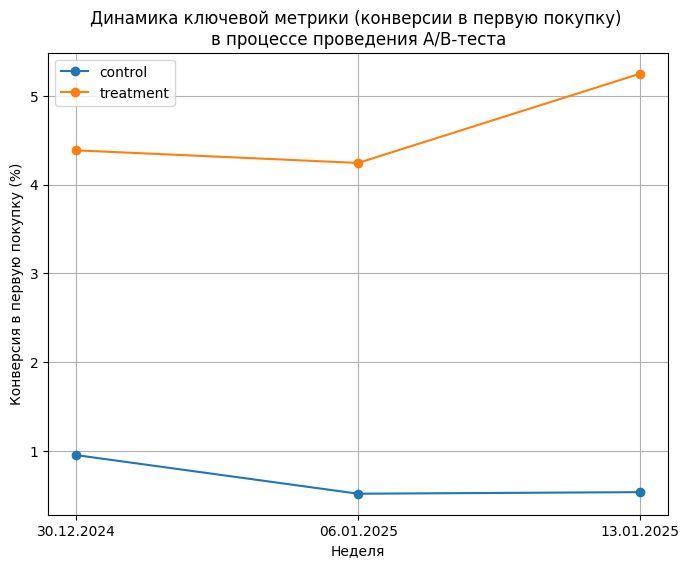

In [17]:
# Изучим, как проходил A/B-тест - как изменялась ключевая метрика и не было ли технических ошибок в каких-то регионах или на устройствах

# Зададим окно наблюдения: сколько дней после регистрации ждём первую покупку
window = pd.Timedelta(days=7)

# Обозначим последнюю дату, до которой у нас есть данные
data_end = events_AB['event_date'].max()

# Создадим дополнительный столбец: покупка считается, только если она была в течение окна после регистрации
time_to_order = first_purchases['first_order_date'] - first_purchases['registration_date']
first_purchases['has_order_in_window'] = (time_to_order <= window).astype(int)

# Оставляем только пользователей, у которых окно целиком помещается в данные
first_purchases_window = first_purchases[first_purchases['registration_date'] + window <= data_end].copy()

# Сгруппируем данные и рассчитаем конверсию за каждую неделю эксперимента
conversion_dynamic = first_purchases_window.groupby(['cohort_week', 'group'])['has_order_in_window'].mean().reset_index(name='conversion')
conversion_dynamic['conversion'] = conversion_dynamic['conversion'] * 100

# Посмотрим также, сколько вообще было покупателей
buyers_dynamic = first_purchases_window.groupby(['cohort_week', 'group'])['has_first_order'].agg(['sum', 'count']).reset_index()
buyers_dynamic = buyers_dynamic.rename(columns={'sum': 'buyers', 'count': 'users_count'})
display(buyers_dynamic)

# Построим график
plt.figure(figsize=(8,6))
for group in conversion_dynamic['group'].unique():
    df_plot = conversion_dynamic[conversion_dynamic['group'] == group]
    plt.plot(df_plot['cohort_week'], df_plot['conversion'], marker='o', label=group)

plt.title('Динамика ключевой метрики (конверсии в первую покупку) \nв процессе проведения A/B-теста')
plt.xlabel('Неделя')
plt.ylabel('Конверсия в первую покупку (%)')
weeks = pd.to_datetime(conversion_dynamic['cohort_week'].unique())
plt.xticks(weeks, weeks.strftime('%d.%m.%Y'))
plt.grid()
plt.legend()
plt.show()

In [18]:
# Посмотрим на эту же динамику по дням

# Уберём время в дате регистрации пользователя
first_purchases['reg_day'] = first_purchases['registration_date'].dt.normalize()


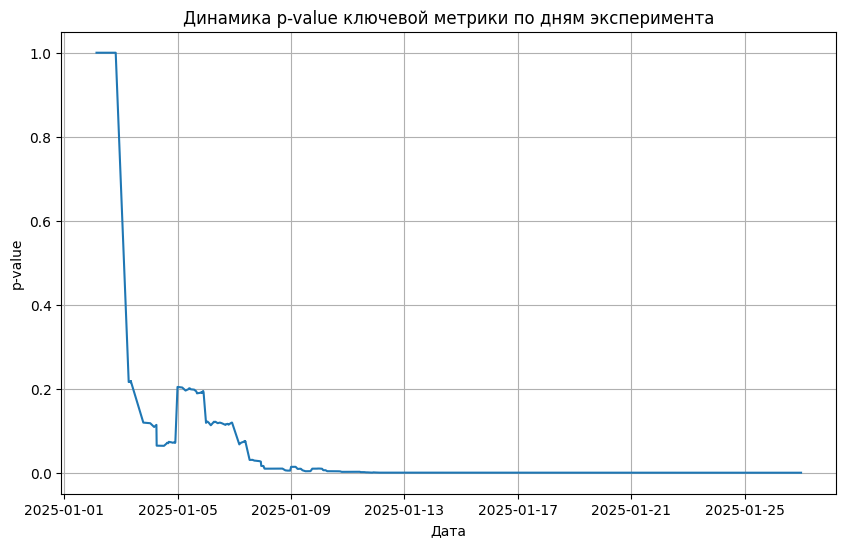

In [19]:
# Посмотрим на поведение p-value ключевой метрики в процессе эксперимента

# Создадим пустой список для наполнения записями
pval_records = []

# Пройдёмся по датасету и рассчитаем p-value по дням 
for current_date in sorted(events_AB['event_date'].unique()):
    # Отберём всех пользователей, зарегистрировавшихся до текущей даты
    active_users = first_purchases[first_purchases['registration_date'] <= current_date].copy()

    # Проверим, совершил ли пользователь первую покупку к этой дате
    active_users['has_purchase_to_date'] = (
        (active_users['first_order_date'] <= current_date)
    ).astype(int)

    # Определим успехи и общее количество пользователей
    counts_conversion = active_users.groupby('group')['has_purchase_to_date'].sum()
    nobs_conversion = active_users.groupby('group')['user_id'].count()

    # Защита от деления на ноль, если в первые дни еще никто ничего не купил
    if (nobs_conversion['treatment'] == 0 or nobs_conversion['control'] == 0
            or counts_conversion['treatment'] == 0 or counts_conversion['control'] == 0):
        p_value = 1.0
    else:
        # Используем z-тест пропорций
        _, p_value = proportions_ztest(counts_conversion[['treatment', 'control']], nobs_conversion[['treatment', 'control']])

    # Запишем получившееся p-value в список
    pval_records.append({
        'date': current_date,
        'p_value': p_value
    })

# Соберём данные в датафрейм
pvalue_df = pd.DataFrame(pval_records)

# Построим график
plt.figure(figsize=(10,6))
plt.plot(pvalue_df['date'], pvalue_df['p_value'])
plt.title('Динамика p-value ключевой метрики по дням эксперимента')
plt.xlabel('Дата')
plt.ylabel('p-value')
plt.grid()
plt.show()

In [20]:
# Посмотрим на первую вспомогательную метрику - ARPU

# Добавим в таблицу users информацию о группах пользователей
users_AB = pd.merge(users_AB, split_users_AB[['user_id', 'group']], on='user_id', how='left')

# Добавим в таблицу orders информацию о группах пользователей
orders_AB = pd.merge(orders_AB, split_users_AB[['user_id', 'group']], on='user_id', how='left')

# Сгруппируем данные 
total_revenue_AB = orders_AB.groupby(['group', 'user_id'])['revenue'].sum().reset_index(name='total_revenue')

# Добавим к информации о выручке информацию о пользователях
arpu_df_AB = pd.merge(users_AB, total_revenue_AB, on=['group', 'user_id'], how='left')

# Заменяем нулями выручку от пользователей без заказов
arpu_df_AB['total_revenue'] = arpu_df_AB['total_revenue'].fillna(0)

# Для удобства запишем в переменные контрольную и тестовую группы
control_arpu = arpu_df_AB[arpu_df_AB['group'] == 'control']['total_revenue']
treatment_arpu = arpu_df_AB[arpu_df_AB['group'] == 'treatment']['total_revenue']

# Используем t-тест
_, p_value = ttest_ind(treatment_arpu, control_arpu, equal_var=False)

# Соберём датафрейм
proxy_metric_1 = pd.DataFrame([{
    'Group A': 'control',
    'Group B': 'treatment',
    'ARPU A': round(control_arpu.mean(), 2),
    'ARPU B': round(treatment_arpu.mean(), 2),
    'Absolute lift': round(treatment_arpu.mean() - control_arpu.mean(), 2),
    'Relative lift (%)': round((treatment_arpu.mean() / control_arpu.mean() - 1) * 100, 2),
    'p-value': round(p_value, 4)
}])

display(proxy_metric_1)

,Group A,Group B,ARPU A,ARPU B,Absolute lift,Relative lift (%),p-value
0,control,treatment,12.59,131.25,118.66,942.71,0.0


In [21]:
# Посмотрим на вторую вспомогательную метрику - ARPPU

# Возьмём уже созданный датафрейм total_revenue_AB
arppu_df_AB = total_revenue_AB 

# Заменим нулями выручку от пользователей без заказов
arppu_df_AB['total_revenue'] = arppu_df_AB['total_revenue'].fillna(0)

# Для удобства запишем в переменные контрольную и тестовую группы
control_arppu = arppu_df_AB[arppu_df_AB['group'] == 'control']['total_revenue']
treatment_arppu = arppu_df_AB[arppu_df_AB['group'] == 'treatment']['total_revenue']

# Используем t-тест
_, p_value = ttest_ind(treatment_arppu, control_arppu, equal_var=False)

# Соберём датафрейм
proxy_metric_2 = pd.DataFrame([{
    'Group A': 'control',
    'Group B': 'treatment',
    'ARPPU A': round(control_arppu.mean(), 2),
    'ARPPU B': round(treatment_arppu.mean(), 2),
    'Absolute lift': round(treatment_arppu.mean() - control_arppu.mean(), 2),
    'Relative lift (%)': round((treatment_arppu.mean() / control_arppu.mean() - 1) * 100, 2),
    'p-value': round(p_value, 4)
}])

display(proxy_metric_2)

,Group A,Group B,ARPPU A,ARPPU B,Absolute lift,Relative lift (%),p-value
0,control,treatment,1182.42,1748.0,565.58,47.83,0.0493


In [22]:
# Посмотрим на третью вспомогательную метрику - AOV
# Важно: это не средняя выручка маркетплейса с одного заказа, а именно средний чек одного заказа

# Возьмём датасет orders_AB, так как там есть всё, что нам нужно
aov_df = orders_AB[['order_id', 'total_price', 'group']]

# Для удобства запишем в переменные контрольную и тестовую группы
control_aov = aov_df[aov_df['group'] == 'control']['total_price']
treatment_aov = aov_df[aov_df['group'] == 'treatment']['total_price']

# Используем t-тест
_, p_value = ttest_ind(treatment_aov, control_aov, equal_var=False)

# Соберём датафрейм
proxy_metric_3 = pd.DataFrame([{
    'Group A': 'control',
    'Group B': 'treatment',
    'AOV A': round(control_aov.mean(), 2),
    'AOV B': round(treatment_aov.mean(), 2),
    'Absolute lift': round(treatment_aov.mean() - control_aov.mean(), 2),
    'Relative lift (%)': round((treatment_aov.mean() / control_aov.mean() - 1) * 100, 2),
    'p-value': round(p_value, 4)
}])

display(proxy_metric_3)

,Group A,Group B,AOV A,AOV B,Absolute lift,Relative lift (%),p-value
0,control,treatment,15765.54,16647.61,882.07,5.59,0.7872


In [23]:
# Посмотрим на барьерную метрику - общую выручку от пользователей TikTok

# p-value для всей выручки (одного числа) мы посчитать не можем, поэтому будем считать его как для ARPU
_, p_value = ttest_ind(treatment_arpu, control_arpu, equal_var=False)

# Соберём датафрейм
barrier_metric = pd.DataFrame([{
    'Group A': 'control',
    'Group B': 'treatment',
    'Users A': len(control_arpu),
    'Users B': len(treatment_arpu),
    'Total revenue A': round(control_arpu.sum(), 2), # общая выручка
    'Total revenue B': round(treatment_arpu.sum(), 2),
    'Revenue per user A': round(control_arpu.mean(), 2), # выручка на пользователя - чтобы не зависеть от размера группы
    'Revenue per user B': round(treatment_arpu.mean(), 2),
    'Absolute revenue per user lift': round(treatment_arpu.mean() - control_arpu.mean(), 2), # лифты считаем тоже по выручке на пользователя
    'Relative revenue per user lift (%)': round((treatment_arpu.mean() / control_arpu.mean() - 1) * 100, 2),
    'p-value': round(p_value, 4)
}])

display(barrier_metric)

,Group A,Group B,Users A,Users B,Total revenue A,Total revenue B,Revenue per user A,Revenue per user B,Absolute revenue per user lift,Relative revenue per user lift (%),p-value
0,control,treatment,1503,1465,18918.65,192279.85,12.59,131.25,118.66,942.71,0.0


## Выводы по этапу 5

**Выводы**

A/B-тест шёл с 1 по 26 января 2025 года. В нём участвовали 2968 новых пользователей из TikTok: 1503 в контрольной группе и 1465 в тестовой. Пользователей, попавших в обе группы, нет. Группы распределены почти поровну: 50.6% в контрольной и 49.4% в тестовой. Конверсия в тестовой группе была выше в каждую неделю теста, а p-value опустился ниже 0.05 уже в первую неделю эксперимента.

**Ключевая метрика - конверсия в первую покупку**

Конверсия в контрольной группе - 1.06%, в тестовой - 7.51%: на 6.4 п.п. выше, то есть примерно в 7 раз. Результат статистически значим (p-value < 0.001).

**Вспомогательная метрика 1 - ARPU**

ARPU в тестовой группе примерно в 10 раз выше, чем в контрольной. Результат статистически значим (p-value < 0.001): покупателей стало больше, поэтому выросла и выручка на пользователя.

**Вспомогательная метрика 2 - ARPPU**

ARPPU в тестовой группе примерно на 48% выше, чем в контрольной, но p-value = 0.049 - на самой границе значимости, а покупателей в контрольной группе всего 16. Поэтому этот результат ненадёжен.

**Вспомогательная метрика 3 - AOV**

Средний чек статистически значимо не отличается (p-value = 0.79): покупатели тратят на один заказ примерно столько же.

**Барьерная метрика - общая выручка от пользователей TikTok**

Сравнивать просто две суммы нерепрезентативно: из-за различий размера групп результат может сильно скакать. Поэтому общую выручку я показала только для информации, а тест проводила по ARPU. Выручка от тестовой группы примерно в 10 раз больше, чем от контрольной. Но в ней не учтена стоимость бонуса, поэтому пока нельзя сказать, выгоден ли бонус для маркетплейса.

**Ограничения эксперимента**

- Перед тестом не были рассчитаны размер выборки и MDE.
- В контрольной группе всего 16 покупателей, поэтому результаты по ARPPU и AOV ненадёжны.
- Тест проходил в новогодние праздники - это нетипичный период.

**Рекомендации**

1. Посчитать стоимость бонусов и сравнить чистую выручку (выручка минус стоимость бонуса) в двух группах.
2. Если бонус окупается - раскатить его на всех пользователей TikTok. Если нет - перезапустить тест вне праздничного периода, заранее рассчитав размер выборки.
3. Проверить, как логируются заказы с бонусом и почему не совпадают данные заказов и событий.

## Conclusion (ENG version)

**Goal:** check if a first-purchase bonus increases first-purchase conversion
for new users from TikTok.

**Test setup:**
- 2,968 new TikTok users registered from January 1 to January 26, 2025:
  1,503 in the control group and 1,465 in the treatment group
- No users are in both groups. The groups are almost equal:
  50.6% in control and 49.4% in treatment
- Conversion was higher in the treatment group in every week of the test,
  and the p-value fell below 0.05 already in the first week

**Primary metric — first-purchase conversion:**
- Control: 1.06%, treatment: 7.51% (+6.4 percentage points, about 7 times higher)
- The difference is statistically significant (p < 0.001)

**Secondary metrics:**
- ARPU is about 10 times higher in the treatment group (p < 0.001):
  more users buy, so revenue per user grows
- ARPPU is about 48% higher in the treatment group, but p = 0.049 is very close
  to the threshold, and there are only 16 buyers in the control group.
  This result is not reliable
- AOV does not differ significantly (p = 0.79): buyers spend about the same
  per order

**Guardrail metric — total revenue from TikTok users:**
Revenue in the treatment group is about 10 times higher. But this revenue
does not include the cost of the bonus, so we cannot say yet
if the bonus is profitable.

**Limitations:**
- There was no sample size or MDE calculation before the test
- There are only 16 buyers in the control group, so the results
  for ARPPU and AOV are not reliable
- The test ran during the New Year holidays, which is not a typical period

**Recommendations:**
1. Calculate the bonus cost and compare net revenue (revenue minus bonus cost)
   in the two groups
2. If the bonus pays back, roll it out to all TikTok users. If not, rerun the test
   outside the holiday period with a sample size calculated in advance
5. Check how orders with the bonus are logged and why orders and events
   do not match